In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
#1. 실습코드00: ITK-SNAP으로 day15를 day0에 registration을 진행한 결과파일을 불러와서 같은 단면을 day0, day15에 대해 display하여 비교하기.
import nibabel as nib

ct_base   = nib.load('volume-covid19-A-0700_day000.nii.gz').get_fdata()        # day00 원본 (ct_base 정의 추가)
ct_FU     = nib.load('volume-covid19-A-0700_day015.nii.gz').get_fdata()        # day15 원본
ct_FU_reg = nib.load("'volume-covid19-A-0700 day00_day015.nii.gz").get_fdata()  # 등록된 day15 이미지

print(ct_base.shape, ct_FU.shape, ct_FU_reg.shape)


(512, 512, 70) (512, 512, 67) (512, 512, 70)


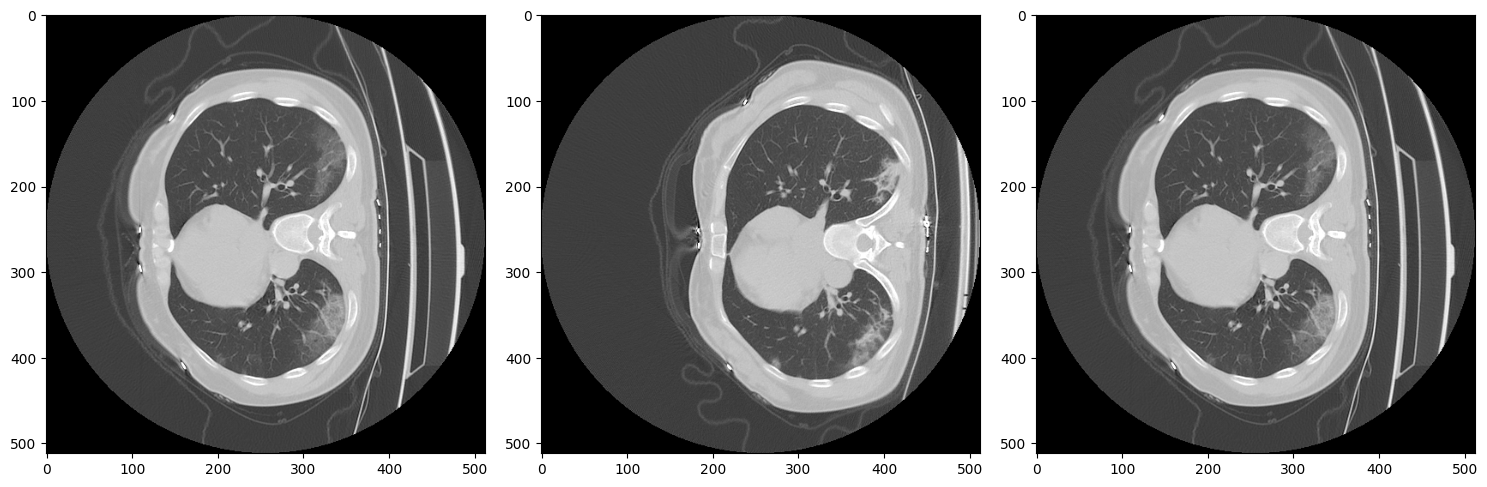

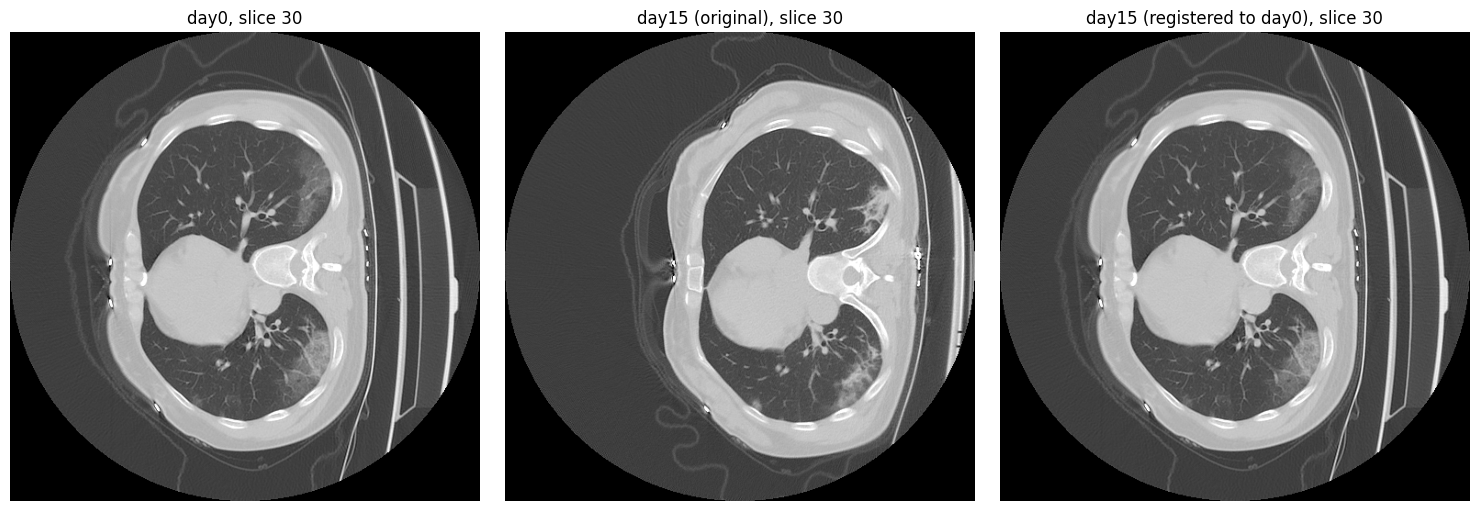

In [8]:
plt.figure(figsize=(15,5))
plt.subplot(131)
plt.imshow(ct_base[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(132)
plt.imshow(ct_FU[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.subplot(133)
plt.imshow(ct_FU_reg[:,:,30],vmin=-1500,vmax=500,cmap='gray')
plt.tight_layout()
plt.show()
titles = ['day0', 'day15 (original)', 'day15 (registered to day0)']
vols = [ct_base, ct_FU, ct_FU_reg]

plt.figure(figsize=(15,5))
for i, (v, t) in enumerate(zip(vols, titles)):
    plt.subplot(1, 3, i+1)
    plt.imshow(v[:,:,30], vmin=-1500, vmax=500, cmap='gray')
    plt.title(f'{t}, slice 30')
    plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
 #실습코드01: Exercise 1. local histogram equalization을 통해 숨겨진 패턴 확인하기
 from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [19]:
import os
imgpath = '/content/drive/MyDrive/class/DIP1/DIP4E'
#os.listdir(imgpath)


In [32]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)   # Drive 다시 연결 (최신 상태 반영)

import glob
found = glob.glob('/content/drive/MyDrive/**/*idden*', recursive=True)
print(found)

Mounted at /content/drive
['/content/drive/MyDrive/DIP4E/hidden-symbols.tif']


In [34]:
f = plt.imread('/content/drive/MyDrive/DIP4E/hidden-symbols.tif')
print(f.shape, f.dtype)

(256, 256) uint8


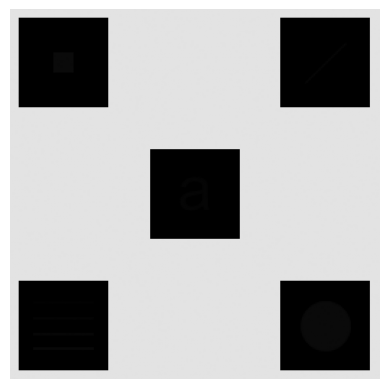

In [44]:
plt.imshow(f,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

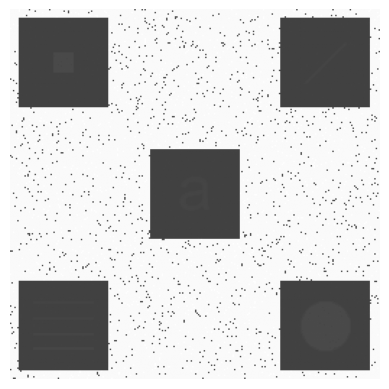

In [45]:
f_eq = histogram_equalization(f)
plt.imshow(f_eq,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()

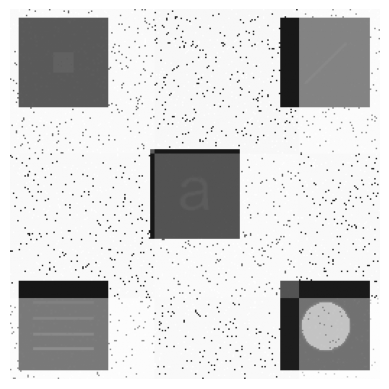

In [48]:
N = 100
f_eq_local = np.zeros_like(f)
for x in np.arange(0,256,N):
  for y in np.arange(0,256,N):
    f_eq_local[x:x+N,y:y+N] = histogram_equalization(f[x:x+N,y:y+N])

plt.imshow(f_eq_local,vmin=0,vmax=255,cmap='gray')
plt.axis('off')
plt.show()


In [49]:
# 3. 실습코드01: Exercise 2. 본인의 사진을 grayscale image로 불러온 후, 서로 다른 kernel size에 대한 LPF결과 비교

In [54]:
from skimage.io import imread

f = imread('/content/1000068215.jpg', as_gray=True)
print(f.shape, f.dtype, f.min(), f.max())

(2252, 4000) float64 0.0 1.0


In [57]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy import signal
from skimage.io import imread

original size: (2252, 4000) float64
cropped size: (600, 600)


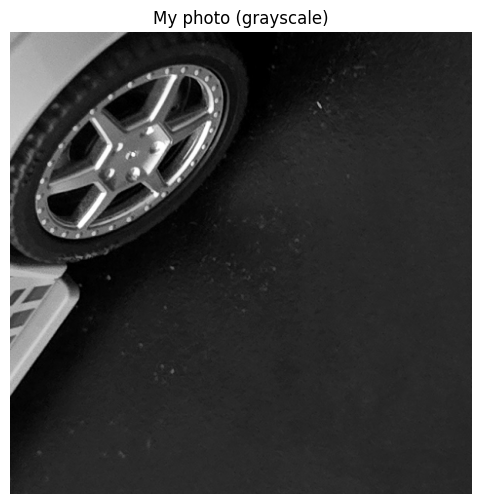

In [58]:
f = imread('/content/1000068215.jpg', as_gray=True)   # 0~1 float
f = f * 255                                            # 0~255 범위로 변환
print('original size:', f.shape, f.dtype)

# 휴대폰 사진은 커서 계산이 오래 걸리므로 가운데 600x600만 사용
H, W = f.shape
c = 300
f = f[H//2-c:H//2+c, W//2-c:W//2+c]
print('cropped size:', f.shape)

plt.figure(figsize=(6, 6))
plt.imshow(f, cmap='gray', vmin=0, vmax=255)
plt.title('My photo (grayscale)')
plt.axis('off')
plt.show()

In [59]:
sizes = [3, 7, 15, 31]      # 가운데 픽셀이 있도록 홀수 크기 사용
results = {}

for N in sizes:
    wb = np.ones((N, N)) / (N * N)          # N x N 평균 필터
    s0 = time.time()
    results[N] = signal.convolve2d(f, wb, mode='same', boundary='symm')
    print(f'box size {N:2d}: computation time = {time.time() - s0:.3f} sec')

box size  3: computation time = 0.021 sec
box size  7: computation time = 0.066 sec
box size 15: computation time = 0.227 sec
box size 31: computation time = 0.816 sec


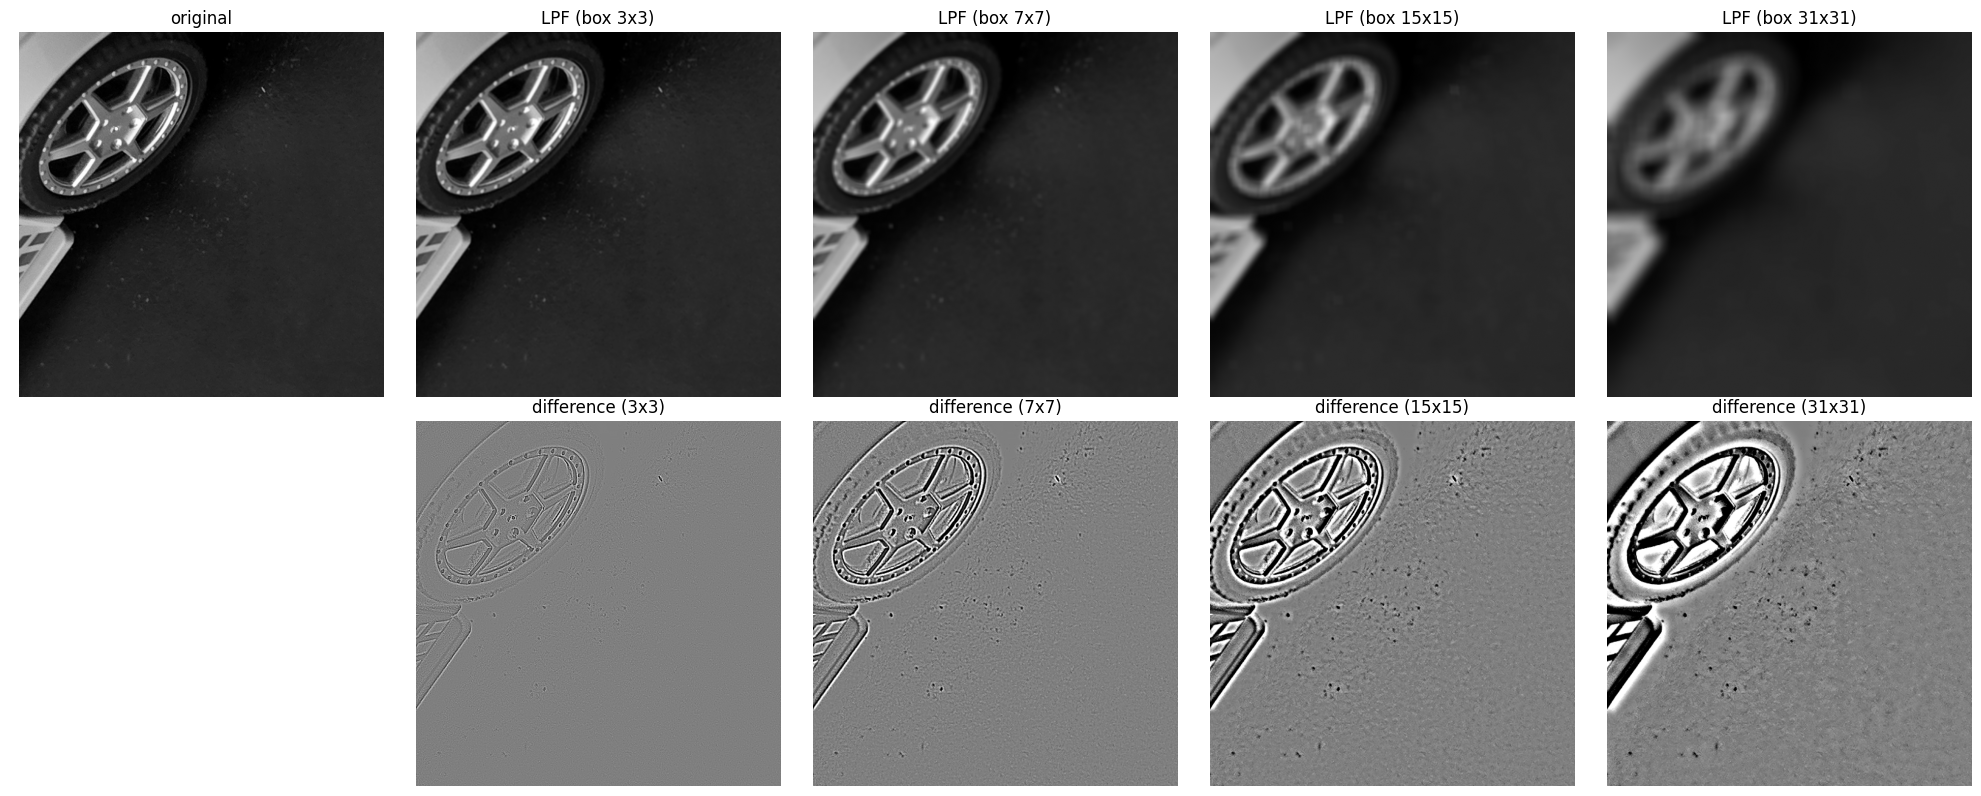

In [60]:
fig, ax = plt.subplots(2, len(sizes) + 1, figsize=(20, 8))

ax[0, 0].imshow(f, cmap='gray', vmin=0, vmax=255)
ax[0, 0].set_title('original')
ax[1, 0].axis('off')

for i, N in enumerate(sizes):
    ax[0, i+1].imshow(results[N], cmap='gray', vmin=0, vmax=255)
    ax[0, i+1].set_title(f'LPF (box {N}x{N})')
    ax[1, i+1].imshow(results[N] - f, cmap='gray', vmin=-30, vmax=30)
    ax[1, i+1].set_title(f'difference ({N}x{N})')

for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()

original size: (2252, 4000)
resized size: (337, 600)


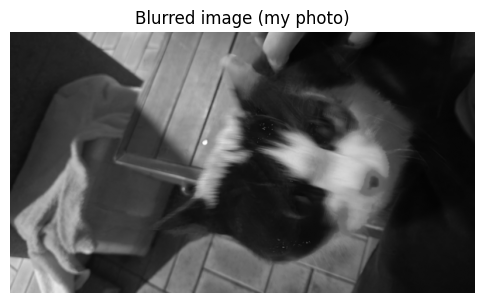

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from skimage.io import imread
from skimage.transform import resize

f = imread('/content/1000066841.jpg', as_gray=True) * 255
print('original size:', f.shape)

scale = 600 / max(f.shape)
f = resize(f, (int(f.shape[0] * scale), int(f.shape[1] * scale)), anti_aliasing=True)
print('resized size:', f.shape)

plt.figure(figsize=(6, 6))
plt.imshow(f, cmap='gray', vmin=0, vmax=255)
plt.title('Blurred image (my photo)')
plt.axis('off')
plt.show()

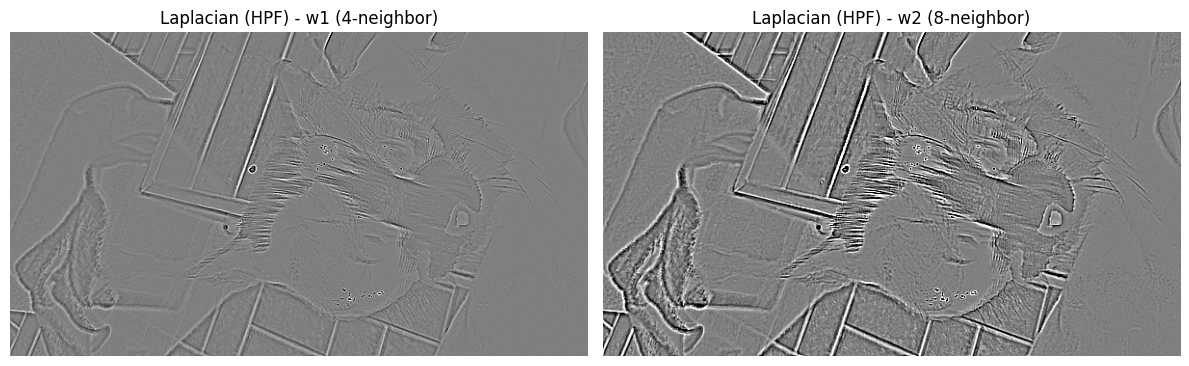

In [65]:
kernels = {
    'w1 (4-neighbor)': np.array([[0, 1, 0],
                                 [1, -4, 1],
                                 [0, 1, 0]], dtype=float),
    'w2 (8-neighbor)': np.array([[1, 1, 1],
                                 [1, -8, 1],
                                 [1, 1, 1]], dtype=float),
}

plt.figure(figsize=(12, 6))
for i, (name, w) in enumerate(kernels.items()):
    lap = signal.convolve2d(f, w, mode='same', boundary='symm')
    plt.subplot(1, 2, i + 1)
    plt.imshow(lap, cmap='gray', vmin=-50, vmax=50)
    plt.title(f'Laplacian (HPF) - {name}')
    plt.axis('off')
plt.tight_layout()
plt.show()

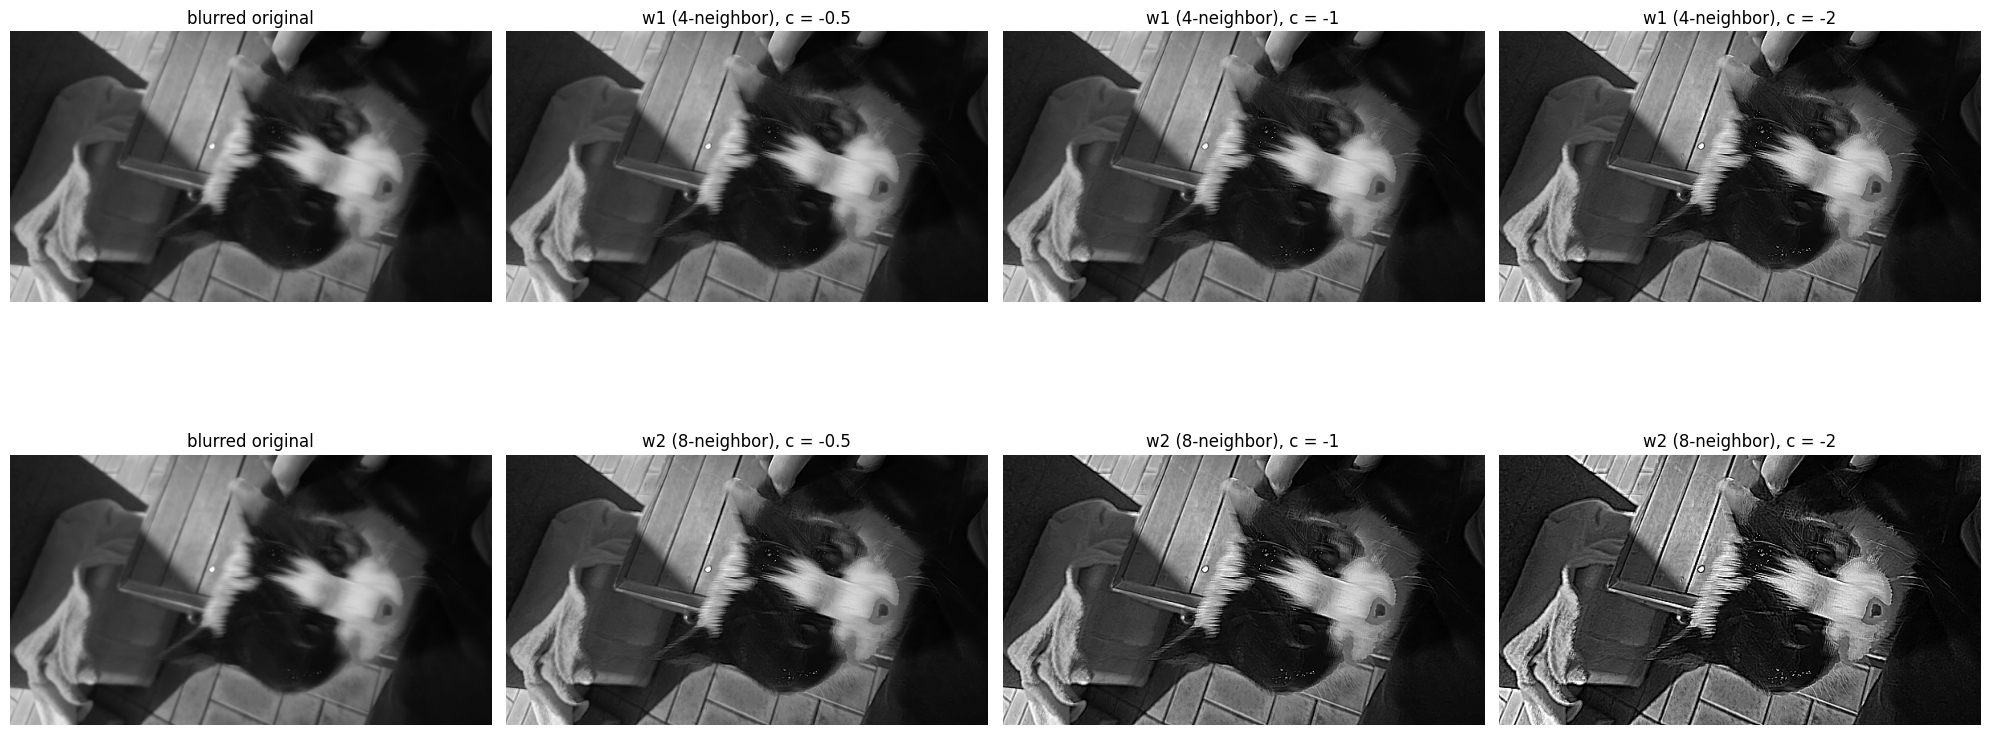

In [66]:
cs = [-0.5, -1, -2]

fig, ax = plt.subplots(len(kernels), len(cs) + 1, figsize=(20, 10))
for i, (name, w) in enumerate(kernels.items()):
    lap = signal.convolve2d(f, w, mode='same', boundary='symm')

    ax[i, 0].imshow(f, cmap='gray', vmin=0, vmax=255)
    ax[i, 0].set_title('blurred original')

    for j, c in enumerate(cs):
        g = np.clip(f + c * lap, 0, 255)          # g = f + c * Laplacian
        ax[i, j+1].imshow(g, cmap='gray', vmin=0, vmax=255)
        ax[i, j+1].set_title(f'{name}, c = {c}')

for a in ax.ravel():
    a.axis('off')
plt.tight_layout()
plt.show()